# analysis

## re-cluster

In [1]:
# 加载所需模块
import snapatac2 as snap
import scanpy as sc
import scanpy.external as sce

In [2]:
data = sc.read_h5ad('./processed/adata.h5ad')
data

AnnData object with n_obs × n_vars = 1641866 × 36601
    obs: 'dataset', 'barcode', 'sample', 'cellType_raw', 'cellType_raw_level1', 'cellType_raw_level2', 'cellType_raw_level3', 'cellType_scarch_level3', 'cellType_actinn_level3', 'cellType_celltypist_level3', 'cellType_scmap_level3', 'cellType_singlecellnet_level3', 'cellType_scpred_level3', 'cellType_singler_level3', 'cellType_chetah_level3', 'cellType_scarch_level2', 'cellType_actinn_level2', 'cellType_celltypist_level2', 'cellType_scmap_level2', 'cellType_singlecellnet_level2', 'cellType_scpred_level2', 'cellType_singler_level2', 'cellType_chetah_level2', 'tissue', 'disease_name', 'disease', 'age', 'age_stage', 'sex', 'technology', 'final_ann'

In [7]:
data.obs['final_ann'] = [item.replace(" ", "_") for item in data.obs['final_ann'].tolist()]
cell = list(set(data.obs['final_ann'].tolist()))
cell

['DC',
 'T_cells',
 'pDC',
 'B_cells',
 'Plasma_cells',
 'ILC',
 'Cycling_cells',
 'B-cell_lineage',
 'Monocytes',
 'Macrophages',
 'Erythroid',
 'Early_MK',
 'HSC/MPP',
 'Mast_cells']

In [5]:
# 部分细胞类型细胞数少，n_pcs需要调整
# HSC/MPP注意保存时报错
# for i in range(len(cell)):
#     print(i)
#     print(cell[i])
#     rna = data[data.obs['final_ann'] == cell[i]]
#     sc.pp.normalize_total(rna, target_sum=1e4)
#     sc.pp.log1p(rna)
#     sc.pp.highly_variable_genes(rna, min_mean=0.0125, max_mean=3, min_disp=0.5)
#     rna = rna[:, rna.var.highly_variable]
#     snap.tl.spectral(rna, features=None)
#     rna.obsm['X_pca'] = rna.obsm['X_spectral']
#     sce.pp.harmony_integrate(rna, 'sample')
#     rna.obsm['X_pca'] = rna.obsm['X_pca_harmony']
#     sc.pp.neighbors(rna, n_neighbors=10, n_pcs=30)
#     sc.tl.umap(rna)
#     rna.write_h5ad('./processed/subcluster/'+cell[i]+'.h5ad')

0
DC
1
pDC
2
Plasma cells
3
ILC
4
Cycling cells
5
Early MK
6
Monocytes
7
Macrophages
8
T cells
9
Erythroid
10
B cells
11
HSC/MPP
12
B-cell lineage
13
Mast cells


In [41]:
    rna = data[data.obs['final_ann'] == 'ILC']
    sc.pp.normalize_total(rna, target_sum=1e4)
    sc.pp.log1p(rna)
    sc.pp.highly_variable_genes(rna, min_mean=0.0125, max_mean=3, min_disp=0.5)
    rna = rna[:, rna.var.highly_variable]
    snap.tl.spectral(rna, features=None)
    rna.obsm['X_pca'] = rna.obsm['X_spectral']
    sce.pp.harmony_integrate(rna, 'sample')
    rna.obsm['X_pca'] = rna.obsm['X_pca_harmony']
    sc.pp.neighbors(rna, n_neighbors=10, n_pcs=30)
    sc.tl.umap(rna)
    rna.write_h5ad('./processed/subcluster/'+'ILC'+'.h5ad')

/home/qiaolibo/miniconda3/envs/scanpy/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:207: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)
/home/qiaolibo/miniconda3/envs/scanpy/lib/python3.11/site-packages/snapatac2/tools/_embedding.py:292: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns['spectral_eigenvalue'] = evals
2024-12-27 09:19:17,809 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2024-12-27 09:19:17 - INFO - Computing initial centroids with sklearn.KMeans...
2024-12-27 09:19:22,476 - harmonypy - INFO - sklearn.KMeans initialization complete.
2024-12-27 09:19:22 - INFO - sklearn.KMeans initialization complete.
2024-12-27 09:19:22,803 - harmonypy - INFO - Iteration 1 of 10
2024-12-27 09:19:22 - INFO - Iteration 1 of 10
2024-12-27 09:20:19,118 - harmonypy - INFO - Iteration 2 of 10
2024-12-27 09:20:19 - INFO - Iteration 2 of 10
2024-12-2

In [60]:
rna = sc.read_h5ad('./processed/subcluster/T_cells.h5ad')
rna.obs['final_ann'].value_counts()

final_ann
T_cells    1115932
Name: count, dtype: int64

In [ ]:
# import snapatac2 as snap
# import scanpy as sc
# import scanpy.external as sce

# data = sc.read_h5ad('./processed/adata.h5ad')
# data.obs['final_ann'] = [item.replace(" ", "_") for item in data.obs['final_ann'].tolist()]
# cell = list(set(data.obs['final_ann'].tolist()))

# for i in range(len(cell)):
#     print(i)
#     print(cell[i])
#     rna = data[data.obs['final_ann'] == cell[i]]
#     sc.pp.normalize_total(rna, target_sum=1e4)
#     sc.pp.log1p(rna)
#     sc.pp.highly_variable_genes(rna, min_mean=0.0125, max_mean=3, min_disp=0.5)
#     rna = rna[:, rna.var.highly_variable]
#     snap.tl.spectral(rna, features=None)
#     rna.obsm['X_pca'] = rna.obsm['X_spectral']
#     sce.pp.harmony_integrate(rna, 'sample')
#     rna.obsm['X_pca'] = rna.obsm['X_pca_harmony']
#     sc.pp.neighbors(rna, n_neighbors=10, n_pcs=30)
#     sc.tl.umap(rna)
#     rna.write_h5ad('./processed/subcluster/'+cell[i]+'.h5ad')

## demo for cell annotation

In [44]:
# 计算
rna = sc.read_h5ad('/pool1/liumengmeng/project_blood_scATAC/subset_ann/B_cells.h5ad')
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
sc.pp.highly_variable_genes(rna, min_mean=0.0125, max_mean=3, min_disp=0.5)
rna = rna[:, rna.var.highly_variable]
snap.tl.spectral(rna, features=None)
rna.obsm['X_pca'] = rna.obsm['X_spectral']
sce.pp.harmony_integrate(rna, 'sample')
rna.obsm['X_pca'] = rna.obsm['X_pca_harmony']
sc.pp.neighbors(rna, n_neighbors=10, n_pcs=30)
sc.tl.umap(rna)

/home/qiaolibo/miniconda3/envs/scanpy/lib/python3.11/site-packages/snapatac2/tools/_embedding.py:292: ImplicitModificationWarning:

Trying to modify attribute `._uns` of view, initializing view as actual.

2024-12-26 01:42:53,510 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2024-12-26 01:42:53 - INFO - Computing initial centroids with sklearn.KMeans...
2024-12-26 01:42:58,474 - harmonypy - INFO - sklearn.KMeans initialization complete.
2024-12-26 01:42:58 - INFO - sklearn.KMeans initialization complete.
2024-12-26 01:42:58,787 - harmonypy - INFO - Iteration 1 of 10
2024-12-26 01:42:58 - INFO - Iteration 1 of 10
2024-12-26 01:43:49,070 - harmonypy - INFO - Iteration 2 of 10
2024-12-26 01:43:49 - INFO - Iteration 2 of 10
2024-12-26 01:44:38,863 - harmonypy - INFO - Iteration 3 of 10
2024-12-26 01:44:38 - INFO - Iteration 3 of 10
2024-12-26 01:45:25,530 - harmonypy - INFO - Iteration 4 of 10
2024-12-26 01:45:25 - INFO - Iteration 4 of 10
2024-12-26 01:46:15,372 

In [59]:
# resolution调整分辨率，得到的聚类数会改变
sc.tl.leiden(rna, flavor="igraph", n_iterations=2, resolution=0.1) 

In [60]:
rna

AnnData object with n_obs × n_vars = 103190 × 3617
    obs: 'dataset', 'barcode', 'sample', 'cellType_raw', 'cellType_raw_level1', 'cellType_raw_level2', 'cellType_raw_level3', 'cellType_scarch_level3', 'cellType_actinn_level3', 'cellType_celltypist_level3', 'cellType_scmap_level3', 'cellType_singlecellnet_level3', 'cellType_scpred_level3', 'cellType_singler_level3', 'cellType_chetah_level3', 'cellType_scarch_level2', 'cellType_actinn_level2', 'cellType_celltypist_level2', 'cellType_scmap_level2', 'cellType_singlecellnet_level2', 'cellType_scpred_level2', 'cellType_singler_level2', 'cellType_chetah_level2', 'tissue', 'disease_name', 'disease', 'age', 'age_stage', 'sex', 'technology', 'final_ann', 'leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'spectral_eigenvalue', 'neighbors', 'umap', 'leiden', 'leiden_colors', 'dataset_colors', 'cellType_celltypist_level2_colors', 'disease_name_colors', 'cellType_raw_level3_colors'
    obsm: '

In [ ]:
# 可视化，leiden是聚类，可参考'cellType_raw_level3','cellType_celltypist_level3','cellType_singlecellnet_level3',
sc.pl.umap(rna, color='leiden')

In [ ]:
sc.pl.dotplot(rna, ['ITGAX', 'CD27',  'IGHD', 'TCL1A'], groupby='leiden')

## Confirm details of incorrectly annotated cells

In [1]:
import scanpy as sc

In [2]:
data = sc.read('./processed/subcluster/raw/Mast_cells.h5ad')
data

AnnData object with n_obs × n_vars = 2912 × 4699
    obs: 'dataset', 'barcode', 'sample', 'cellType_raw', 'cellType_raw_level1', 'cellType_raw_level2', 'cellType_raw_level3', 'cellType_scarch_level3', 'cellType_actinn_level3', 'cellType_celltypist_level3', 'cellType_scmap_level3', 'cellType_singlecellnet_level3', 'cellType_scpred_level3', 'cellType_singler_level3', 'cellType_chetah_level3', 'cellType_scarch_level2', 'cellType_actinn_level2', 'cellType_celltypist_level2', 'cellType_scmap_level2', 'cellType_singlecellnet_level2', 'cellType_scpred_level2', 'cellType_singler_level2', 'cellType_chetah_level2', 'tissue', 'disease_name', 'disease', 'age', 'age_stage', 'sex', 'technology', 'final_ann'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p', 'neighbors', 'spectral_eigenvalue', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_spectral', 'X_umap'
    obsp: 'connectivities', 'distances'

In [7]:
data.obs['cellType_raw_level2'].value_counts()

cellType_raw_level2
HSC/MPP           1202
Monocytes          696
Mast cells         507
Erythroid          354
notAvailable        86
ILC                 20
Early MK            20
T cells              9
B-cell lineage       8
DC                   6
B cells              2
Macrophages          1
pDC                  1
Name: count, dtype: int64

In [8]:
mac = sc.read('./processed/subcluster/raw/Macrophages.h5ad')
mac

AnnData object with n_obs × n_vars = 624 × 5510
    obs: 'dataset', 'barcode', 'sample', 'cellType_raw', 'cellType_raw_level1', 'cellType_raw_level2', 'cellType_raw_level3', 'cellType_scarch_level3', 'cellType_actinn_level3', 'cellType_celltypist_level3', 'cellType_scmap_level3', 'cellType_singlecellnet_level3', 'cellType_scpred_level3', 'cellType_singler_level3', 'cellType_chetah_level3', 'cellType_scarch_level2', 'cellType_actinn_level2', 'cellType_celltypist_level2', 'cellType_scmap_level2', 'cellType_singlecellnet_level2', 'cellType_scpred_level2', 'cellType_singler_level2', 'cellType_chetah_level2', 'tissue', 'disease_name', 'disease', 'age', 'age_stage', 'sex', 'technology', 'final_ann'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p', 'neighbors', 'spectral_eigenvalue', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_spectral', 'X_umap'
    obsp: 'connectivities', 'distances'

In [9]:
mac.obs['cellType_raw_level2'].value_counts()

cellType_raw_level2
notAvailable    285
Monocytes       170
HSC/MPP          66
DC               41
Erythroid        19
Macrophages      19
T cells          12
B cells           5
Early MK          4
ILC               2
Plasma cells      1
Name: count, dtype: int64

In [10]:
bl = sc.read('./processed/subcluster/raw/B-cell_lineage.h5ad')
bl

AnnData object with n_obs × n_vars = 529 × 4804
    obs: 'dataset', 'barcode', 'sample', 'cellType_raw', 'cellType_raw_level1', 'cellType_raw_level2', 'cellType_raw_level3', 'cellType_scarch_level3', 'cellType_actinn_level3', 'cellType_celltypist_level3', 'cellType_scmap_level3', 'cellType_singlecellnet_level3', 'cellType_scpred_level3', 'cellType_singler_level3', 'cellType_chetah_level3', 'cellType_scarch_level2', 'cellType_actinn_level2', 'cellType_celltypist_level2', 'cellType_scmap_level2', 'cellType_singlecellnet_level2', 'cellType_scpred_level2', 'cellType_singler_level2', 'cellType_chetah_level2', 'tissue', 'disease_name', 'disease', 'age', 'age_stage', 'sex', 'technology', 'final_ann'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg', 'log1p', 'neighbors', 'spectral_eigenvalue', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_spectral', 'X_umap'
    obsp: 'connectivities', 'distances'

In [11]:
bl.obs['cellType_raw_level2'].value_counts()

cellType_raw_level2
B-cell lineage    260
HSC/MPP           178
notAvailable       81
B cells             8
Erythroid           1
pDC                 1
Name: count, dtype: int64

## Draw a stacked column chart

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib

# 设置中文字体
matplotlib.rcParams['font.sans-serif'] = ['SimHei']  # 使用 SimHei 字体支持中文
matplotlib.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题

# 数据准备
data = {
    'Cell Type': ['T cells', 'notAvailable', 'HSC/MPP', 'Monocytes', 'ILC', 'B cells', 'Erythroid', 
                  'Early MK', 'DC', 'B-cell lineage', 'pDC', 'Plasma cells', 'Cycling cells', 
                  'Macrophages', 'Mast cells'],
    'Color': ['#ff9896', '#cccecf', '#e377c2', '#ffbb78', '#b5bd61', '#1f77b4', '#8c564b', '#aa40fc',
              '#d62728', '#ff7f0e', '#c5b0d5', '#98df8a', '#279e68', '#17becf', '#aec7e8'],
    'Mast cells': [9, 0, 1202, 696, 20, 2, 354, 20, 6, 8, 1, 0, 0, 1, 507],
    'Macrophages': [12, 0, 66, 170, 2, 5, 19, 4, 41, 0, 0, 1, 0, 19, 0],
    'B-cell lineage': [0, 0, 178, 0, 0, 8, 1, 0, 0, 260, 1, 0, 0, 0, 0]
}

df = pd.DataFrame(data)

# 计算比例
groups = ['Mast cells', 'Macrophages', 'B-cell lineage']
for group in groups:
    df[f'{group}_prop'] = df[group] / df[group].sum() * 100

# 创建绘图
fig, ax = plt.subplots(figsize=(10, 6))

# 每组的柱子宽度和位置
bar_width = 0.25
x_positions = [0, 1, 2]

# 为每组绘制堆积柱状图
for i, group in enumerate(groups):
    # 按比例从大到小排序
    temp_df = df[['Cell Type', 'Color', f'{group}_prop']].copy()
    temp_df = temp_df[temp_df[f'{group}_prop'] > 0].sort_values(f'{group}_prop', ascending=True)  # 从小到大排序，便于底部堆积
    
    bottom = 0  # 堆积的底部高度
    for _, row in temp_df.iterrows():
        ax.bar(x_positions[i], row[f'{group}_prop'], bar_width, bottom=bottom, 
               color=row['Color'], label=row['Cell Type'] if i == 0 else None)
        bottom += row[f'{group}_prop']

# 设置图表属性
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['肥大细胞组', '巨噬细胞组', 'B细胞谱系组'])
ax.set_ylabel('比例 (%)')
ax.set_ylim(0, 100)
ax.set_title('各组细胞类型比例（组内按比例从上到下排序）')

# 图例（仅显示一次，避免重复）
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))  # 去除重复标签
ax.legend(by_label.values(), by_label.keys(), loc='center left', bbox_to_anchor=(1, 0.5))

# 调整布局以适应图例
plt.tight_layout()

# 保存图表
plt.savefig('stacked_bar_proportion_sorted.pdf', dpi=300, bbox_inches='tight')
plt.close()

findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
findfont: Generic family 'sans-serif' not found because none of the following families were found: SimHei
/tmp/ipykernel_3853194/643259784.py:61: UserWarning: Glyph 32933 (\N{CJK UNIFIED IDEOGRAPH-80A5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3853194/643259784.py:61: UserWarning: Glyph 22823 (\N{CJK UNIFIED IDEOGRAPH-5927}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3853194/643259784.py:61: UserWarning: Glyph 32454 (\N{CJK UNIFIED IDEOGRAPH-7EC6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3853194/643259784.py:61: UserWarning: Glyph 32990 (\N{CJK UNIFIED IDEOGRAPH-80DE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3853194/643259784.py:61: UserWarning: Glyph 32452 (\N{CJK UNIFIED IDEOGRAPH-7EC4}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
findfont: Generic famil

# visual

In [2]:
import os
import scanpy as sc
import pandas as pd
import numpy as np

## Organize subgroup annotations

In [10]:
lis = os.listdir('./celltype_clustered/')[:11]
lis

['Clustered_Plasmablasts.h5ad',
 'Clustered_HSPC.h5ad',
 'Clustered_Monocytes.h5ad',
 'Clustered_T.h5ad',
 'Clustered_B-cell_lineage.h5ad',
 'Clustered_cycling.h5ad',
 'Clustered_DC.h5ad',
 'Clustered_ILC.h5ad',
 'Clustered_erythroid.h5ad',
 'Clustered_macrophages.h5ad',
 'clustered_B.h5ad']

In [11]:
subcluster = sc.read_h5ad('./celltype_clustered/'+lis[0]).obs[['leiden']]
subcluster

,leiden
Cheong_Cell_2023_1-CGTTATCGTTGTAACG-HDu,Plasmablasts
Cheong_Cell_2023_1-TGACTTCGTAAGGTCC-HDu,Plasmablasts
Cheong_Cell_2023_1-TCTCCTCGTCGTAATG-HDa,Plasmablasts
Cheong_Cell_2023_1-AGCATTTCACTGGCCA-HD_AD,Plasmablasts
Cheong_Cell_2023_1-AGCTTCCTCCAGCACA-HD_AD,Plasmablasts
...,...
Marderstein_Nature_2024-TGTGCTGAGTACCGCA-H_6_A,Plasma cells
Marderstein_Nature_2024-ACTCACTGTACCGTTT-H_7_A,Plasma cells
Marderstein_Nature_2024-CTATTCAGTCGTAAAT-H_7_C,Plasma cells
Marderstein_Nature_2024-GCGAAGTAGATAAAGC-H_7_C,Plasma cells


In [12]:
for i in range(1,11):
    print(i)
    sub = sc.read_h5ad('./celltype_clustered/'+lis[i]).obs[['leiden']]
    subcluster = pd.concat([subcluster, sub])

1
2
3
4
5
6
7
8
9
10


In [13]:
subcluster

,leiden
Cheong_Cell_2023_1-CGTTATCGTTGTAACG-HDu,Plasmablasts
Cheong_Cell_2023_1-TGACTTCGTAAGGTCC-HDu,Plasmablasts
Cheong_Cell_2023_1-TCTCCTCGTCGTAATG-HDa,Plasmablasts
Cheong_Cell_2023_1-AGCATTTCACTGGCCA-HD_AD,Plasmablasts
Cheong_Cell_2023_1-AGCTTCCTCCAGCACA-HD_AD,Plasmablasts
...,...
Marderstein_Nature_2024-TTTGGTAAGAGAGCCG-H_7_C,Memory B cells
Marderstein_Nature_2024-TTTGTCCCACCAACCG-H_7_C,Memory B cells
Marderstein_Nature_2024-TTTGTCTAGACAACGA-H_7_C,Memory B cells
Marderstein_Nature_2024-TTTGTGAAGCCTGACA-H_7_C,Memory B cells


In [14]:
subcluster['leiden'].value_counts()

leiden
Tcm/Naive helper T cells         595478
Type1 helper T cells             221702
Classical monocytes              131780
Tem/Temra cytotoxic T cells      101094
CD16+ NK cells                    86094
Tem/Trm cytotoxic T cells         83556
Naive B cells                     76036
HSC/MPP                           57434
Follicular helper T cells         52863
Regulatory T cells                50399
Non-classical monocytes           20979
Memory B cells                    18912
Early erythroid                   17330
Mono-mac                          16722
ELP                               15847
Transitional NK                   13560
MEMP                              10943
Tcm/Naive cytotoxic T cells       10840
Late erythroid                    10511
ILC3                               6997
Transitional B cells               6989
DC3                                5120
CMP                                4255
Plasmablasts                       4162
Mid erythroid                    

## merge

In [5]:
data = sc.read_h5ad('/pool1/qiaolibo/R_Project/peak_gene/z_others/8_new/processed/adata.h5ad')
data

AnnData object with n_obs × n_vars = 1641866 × 36601
    obs: 'dataset', 'barcode', 'sample', 'cellType_raw', 'cellType_raw_level1', 'cellType_raw_level2', 'cellType_raw_level3', 'cellType_scarch_level3', 'cellType_actinn_level3', 'cellType_celltypist_level3', 'cellType_scmap_level3', 'cellType_singlecellnet_level3', 'cellType_scpred_level3', 'cellType_singler_level3', 'cellType_chetah_level3', 'cellType_scarch_level2', 'cellType_actinn_level2', 'cellType_celltypist_level2', 'cellType_scmap_level2', 'cellType_singlecellnet_level2', 'cellType_scpred_level2', 'cellType_singler_level2', 'cellType_chetah_level2', 'tissue', 'disease_name', 'disease', 'age', 'age_stage', 'sex', 'technology', 'final_ann'

In [19]:
# 42种
# ann = data.obs[['final_ann']]
# dif = list(set(ann.index.tolist()) - set(subcluster.index.tolist()))
# ann_dif = ann.loc[dif,:]
# ann_dif.columns = ['leiden']
# all = pd.concat([subcluster,ann_dif])
# all_sort = all.loc[data.obs_names.tolist(),:]
# all_sort.to_csv('./subcluser.csv')

In [21]:
all_sort = pd.read_csv('./subcluser.csv', index_col=0)
all_sort.replace('Type1 helper T cells', 'Type 1 helper T cells', inplace=True)

In [22]:
data.obs['ann_level3'] = all_sort

In [23]:
# cell level
cell = pd.read_csv('/pool1/qiaolibo/R_Project/peak_gene/z_others/6_ann/origin/sc_105.csv')
cell = cell.applymap(lambda x: x.rstrip() if isinstance(x, str) else x)
cell

,level_1,level_2,level_3
0,HSC/MPP,HSC/MPP,HSC/MPP
1,HSC/MPP,HSC/MPP,CMP
2,HSC/MPP,HSC/MPP,GMP
3,HSC/MPP,HSC/MPP,ELP
4,HSC/MPP,HSC/MPP,MEMP
...,...,...,...
100,Lymphoid,B cells,Pre-B cells
101,Lymphoid,T cells,T cells
102,Lymphoid,T cells,Cytotoxic T cells
103,Lymphoid,T cells,Tem/Effector cytotoxic T cells


In [24]:
result = dict(zip(cell['level_3'], cell['level_1']))
result

{'HSC/MPP': 'HSC/MPP',
 'CMP': 'HSC/MPP',
 'GMP': 'HSC/MPP',
 'ELP': 'HSC/MPP',
 'MEMP': 'HSC/MPP',
 'Megakaryocyte-erythroid-mast cell progenitor': 'HSC/MPP',
 'Neutrophil-myeloid progenitor': 'HSC/MPP',
 'Early lymphoid/T lymphoid': 'HSC/MPP',
 'CD8a/a': 'Lymphoid',
 'CD8a/b(entry)': 'Lymphoid',
 'Follicular helper T cells': 'Lymphoid',
 'CRTAM+ gamma-delta T cells': 'Lymphoid',
 'gamma-delta T cells': 'Lymphoid',
 'MAIT cells': 'Lymphoid',
 'Memory CD4+ cytotoxic T cells': 'Lymphoid',
 'NKT cells': 'Lymphoid',
 'Regulatory T cells': 'Lymphoid',
 'T(agonist)': 'Lymphoid',
 'Tcm/Naive cytotoxic T cells': 'Lymphoid',
 'Tcm/Naive helper T cells': 'Lymphoid',
 'Tem/Trm cytotoxic T cells': 'Lymphoid',
 'Tem/Temra cytotoxic T cells': 'Lymphoid',
 'Trm cytotoxic T cells': 'Lymphoid',
 'Tem/Effector helper T cells': 'Lymphoid',
 'Tem/Effector helper T cells PD1+': 'Lymphoid',
 'Treg(diff)': 'Lymphoid',
 'Type 1 helper T cells': 'Lymphoid',
 'Type 17 helper T cells': 'Lymphoid',
 'B cells': '

In [25]:
all_level1 = all_sort.replace(result)
all_level1

,leiden
Chen_Nat_Methods_2022-AAACAGCCAACTGGCT-lane1,Lymphoid
Chen_Nat_Methods_2022-AAACATGCACAATTAC-lane1,Lymphoid
Chen_Nat_Methods_2022-AAACATGCAGCACGTT-lane1,Lymphoid
Chen_Nat_Methods_2022-AAACATGCATATTGAC-lane1,Lymphoid
Chen_Nat_Methods_2022-AAACCAACAATAGCAA-lane1,Lymphoid
...,...
Marderstein_Nature_2024-TTTGTGTTCACGAATC-H_7_C,Lymphoid
Marderstein_Nature_2024-TTTGTGTTCATGGCCA-H_7_C,Lymphoid
Marderstein_Nature_2024-TTTGTGTTCTGTGCAG-H_7_C,Lymphoid
Marderstein_Nature_2024-TTTGTTGGTAGGTTTG-H_7_C,Lymphoid


In [26]:
all_level1['leiden'].value_counts()

leiden
Lymphoid    1331098
Myeloid      221884
HSC/MPP       88479
others          405
Name: count, dtype: int64

In [27]:
result = dict(zip(cell['level_2'], cell['level_1']))
result

{'HSC/MPP': 'HSC/MPP',
 'T cells': 'Lymphoid',
 'B cells': 'Lymphoid',
 'B-cell lineage': 'Lymphoid',
 'Plasma cells': 'Lymphoid',
 'ILC': 'Lymphoid',
 'ETP': 'Lymphoid',
 'Double-negative thymocytes': 'Lymphoid',
 'Double-positive thymocytes': 'Lymphoid',
 'DC precursor': 'Myeloid',
 'DC': 'Myeloid',
 'pDC precursor': 'Myeloid',
 'pDC': 'Myeloid',
 'Macrophages': 'Myeloid',
 'Monocyte precursor': 'Myeloid',
 'Monocytes': 'Myeloid',
 'Mono-mac': 'Myeloid',
 'MNP': 'Myeloid',
 'Megakaryocyte precursor': 'Myeloid',
 'Early MK': 'Myeloid',
 'Megakaryocytes/platelets': 'Myeloid',
 'Erythrocytes': 'Myeloid',
 'Erythroid': 'Myeloid',
 'Myelocytes': 'Myeloid',
 'Promyelocytes': 'Myeloid',
 'Granulocytes': 'Myeloid',
 'Mast cells': 'Myeloid',
 'Endothelial cells': 'others',
 'Epithelial cells': 'others',
 'Fibroblasts': 'others',
 'Cycling cells': 'others',
 'notAvailable': 'notAvailable'}

In [28]:
all_level1 = data.obs[['final_ann']].replace(result)
all_level1.value_counts()

final_ann
Lymphoid     1331098
Myeloid       221884
HSC/MPP        88479
others           405
Name: count, dtype: int64

In [29]:
data

AnnData object with n_obs × n_vars = 1641866 × 36601
    obs: 'dataset', 'barcode', 'sample', 'cellType_raw', 'cellType_raw_level1', 'cellType_raw_level2', 'cellType_raw_level3', 'cellType_scarch_level3', 'cellType_actinn_level3', 'cellType_celltypist_level3', 'cellType_scmap_level3', 'cellType_singlecellnet_level3', 'cellType_scpred_level3', 'cellType_singler_level3', 'cellType_chetah_level3', 'cellType_scarch_level2', 'cellType_actinn_level2', 'cellType_celltypist_level2', 'cellType_scmap_level2', 'cellType_singlecellnet_level2', 'cellType_scpred_level2', 'cellType_singler_level2', 'cellType_chetah_level2', 'tissue', 'disease_name', 'disease', 'age', 'age_stage', 'sex', 'technology', 'final_ann', 'ann_level3'

In [30]:
data.obs['ann_level1'] = all_level1

In [31]:
data

AnnData object with n_obs × n_vars = 1641866 × 36601
    obs: 'dataset', 'barcode', 'sample', 'cellType_raw', 'cellType_raw_level1', 'cellType_raw_level2', 'cellType_raw_level3', 'cellType_scarch_level3', 'cellType_actinn_level3', 'cellType_celltypist_level3', 'cellType_scmap_level3', 'cellType_singlecellnet_level3', 'cellType_scpred_level3', 'cellType_singler_level3', 'cellType_chetah_level3', 'cellType_scarch_level2', 'cellType_actinn_level2', 'cellType_celltypist_level2', 'cellType_scmap_level2', 'cellType_singlecellnet_level2', 'cellType_scpred_level2', 'cellType_singler_level2', 'cellType_chetah_level2', 'tissue', 'disease_name', 'disease', 'age', 'age_stage', 'sex', 'technology', 'final_ann', 'ann_level3', 'ann_level1'

In [32]:
data.obs[['ann_level1', 'final_ann', 'ann_level3']]

,ann_level1,final_ann,ann_level3
Chen_Nat_Methods_2022-AAACAGCCAACTGGCT-lane1,Lymphoid,T cells,Tcm/Naive helper T cells
Chen_Nat_Methods_2022-AAACATGCACAATTAC-lane1,Lymphoid,T cells,Tcm/Naive helper T cells
Chen_Nat_Methods_2022-AAACATGCAGCACGTT-lane1,Lymphoid,T cells,Tcm/Naive helper T cells
Chen_Nat_Methods_2022-AAACATGCATATTGAC-lane1,Lymphoid,T cells,Type 1 helper T cells
Chen_Nat_Methods_2022-AAACCAACAATAGCAA-lane1,Lymphoid,T cells,Tcm/Naive helper T cells
...,...,...,...
Marderstein_Nature_2024-TTTGTGTTCACGAATC-H_7_C,Lymphoid,ILC,CD16+ NK cells
Marderstein_Nature_2024-TTTGTGTTCATGGCCA-H_7_C,Lymphoid,ILC,Transitional NK
Marderstein_Nature_2024-TTTGTGTTCTGTGCAG-H_7_C,Lymphoid,T cells,Tem/Trm cytotoxic T cells
Marderstein_Nature_2024-TTTGTTGGTAGGTTTG-H_7_C,Lymphoid,T cells,Tem/Trm cytotoxic T cells


## Sankey diagram

In [33]:
df = data.obs[['ann_level1', 'final_ann', 'ann_level3']].copy()
df.columns = ['l1', 'l2', 'l3']
df

,l1,l2,l3
Chen_Nat_Methods_2022-AAACAGCCAACTGGCT-lane1,Lymphoid,T cells,Tcm/Naive helper T cells
Chen_Nat_Methods_2022-AAACATGCACAATTAC-lane1,Lymphoid,T cells,Tcm/Naive helper T cells
Chen_Nat_Methods_2022-AAACATGCAGCACGTT-lane1,Lymphoid,T cells,Tcm/Naive helper T cells
Chen_Nat_Methods_2022-AAACATGCATATTGAC-lane1,Lymphoid,T cells,Type 1 helper T cells
Chen_Nat_Methods_2022-AAACCAACAATAGCAA-lane1,Lymphoid,T cells,Tcm/Naive helper T cells
...,...,...,...
Marderstein_Nature_2024-TTTGTGTTCACGAATC-H_7_C,Lymphoid,ILC,CD16+ NK cells
Marderstein_Nature_2024-TTTGTGTTCATGGCCA-H_7_C,Lymphoid,ILC,Transitional NK
Marderstein_Nature_2024-TTTGTGTTCTGTGCAG-H_7_C,Lymphoid,T cells,Tem/Trm cytotoxic T cells
Marderstein_Nature_2024-TTTGTTGGTAGGTTTG-H_7_C,Lymphoid,T cells,Tem/Trm cytotoxic T cells


In [35]:
df.to_csv('./celltype_l1_l3.csv')

In [72]:
df['l1'] = df['l1'].astype(str) +'l1'
df['l2'] = df['l2'].astype(str) +'l2'
df['l3'] = df['l3'].astype(str) +'l3'

In [73]:
import plotly.graph_objects as go

# 步骤1：统计 l1→l2 的细胞数量
flow_l1_l2 = df.groupby(['l1', 'l2']).size().reset_index(name='count')
# 步骤2：统计 l2→l3 的细胞数量
flow_l2_l3 = df.groupby(['l2', 'l3']).size().reset_index(name='count')

# 合并流量数据
flows = pd.concat([flow_l1_l2, flow_l2_l3], axis=0)

In [74]:
# 提取所有唯一节点（按层级顺序）
nodes_l1 = df['l1'].unique().tolist()
nodes_l2 = df['l2'].unique().tolist()
nodes_l3 = df['l3'].unique().tolist()
all_nodes = nodes_l1 + nodes_l2 + nodes_l3

# 为每个节点分配唯一索引
node_indices = {node: i for i, node in enumerate(all_nodes)}

# 构建链接（source, target, value）
links = []
# 添加 l1→l2 的链接
for _, row in flow_l1_l2.iterrows():
    source = node_indices[row['l1']]
    target = node_indices[row['l2']]
    links.append({'source': source, 'target': target, 'value': row['count']})
# 添加 l2→l3 的链接
for _, row in flow_l2_l3.iterrows():
    source = node_indices[row['l2']]
    target = node_indices[row['l3']]
    links.append({'source': source, 'target': target, 'value': row['count']})

# 转换为桑基图需要的格式
sankey_links = {
    'source': [link['source'] for link in links],
    'target': [link['target'] for link in links],
    'value': [link['value'] for link in links]
}

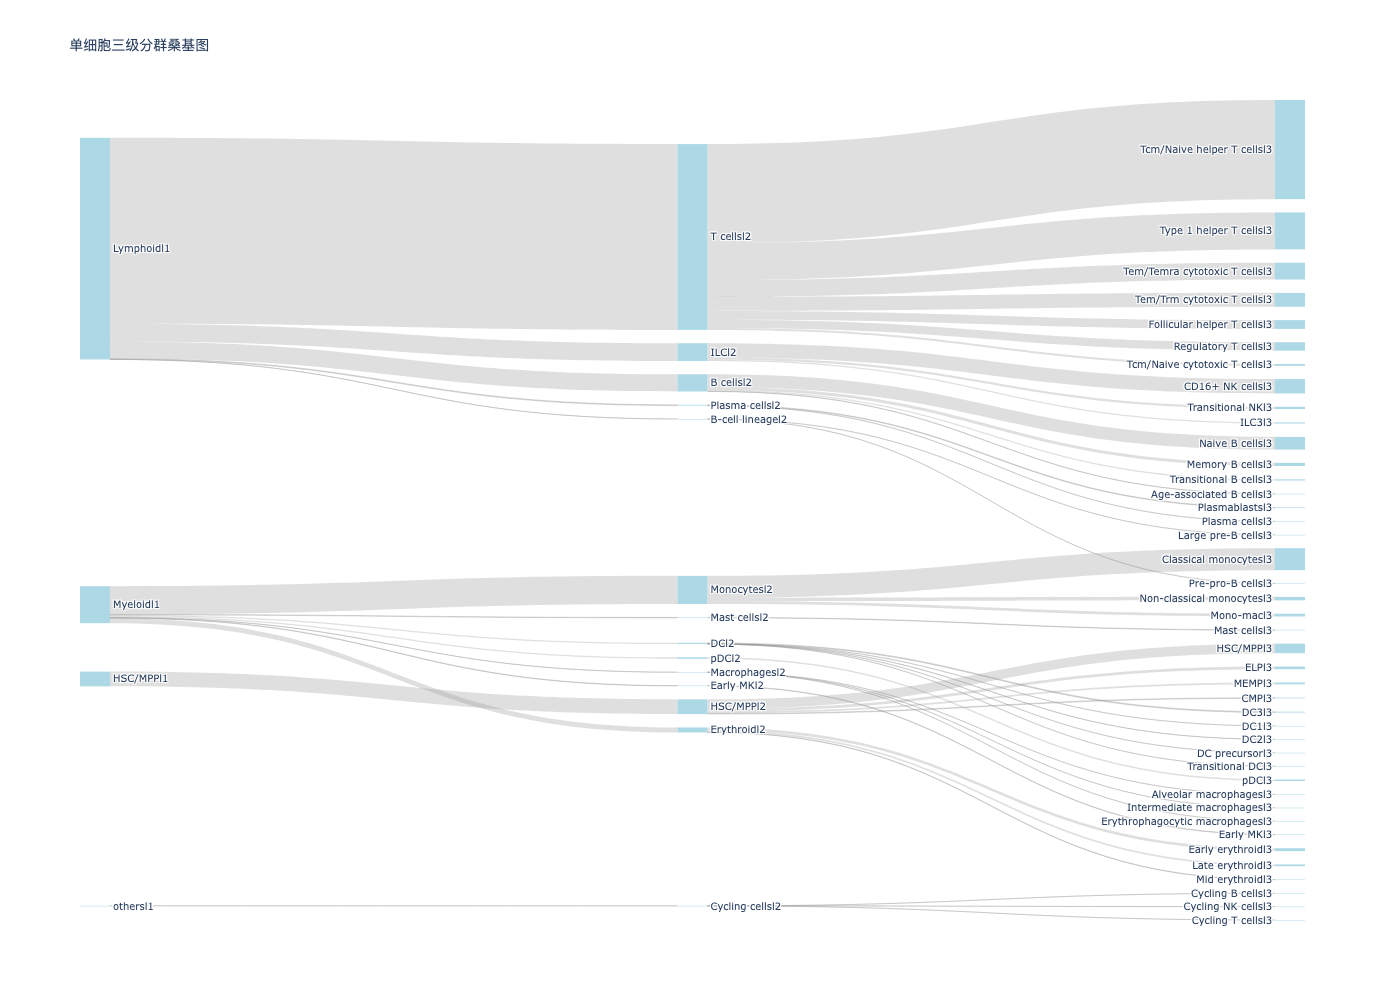

In [84]:
# 创建桑基图对象
fig = go.Figure(go.Sankey(
    node={
        'label': all_nodes,              # 节点名称
        'pad': 20,                       # 节点间距
        'thickness': 30,                 # 节点厚度
        'line': {'color': 'black', 'width': 0},  # 节点边框
        'color': 'lightblue'             # 节点颜色
    },
    link={
        'source': sankey_links['source'],  # 源节点索引
        'target': sankey_links['target'],  # 目标节点索引
        'value': sankey_links['value'],    # 流量值
        'color': 'rgba(150, 150, 150, 0.3)'  # 链接颜色（半透明灰色）
    }
))

# 调整布局
fig.update_layout(
    title="单细胞三级分群桑基图",
    font=dict(size=10),
    width=800,
    height=1000
)
fig.show()
fig.write_image("sankey_plot.pdf", engine="kaleido")

In [ ]:
# 保存为静态图片
fig.write_image("sankey_plot.pdf", engine="kaleido")  # 需安装 kaleido: pip install kaleido

## UMAP

In [3]:
data = sc.read_h5ad('/pool1/qiaolibo/R_Project/peak_gene/z_others/8_new/processed/adata.h5ad')
data

AnnData object with n_obs × n_vars = 1641866 × 36601
    obs: 'dataset', 'barcode', 'sample', 'cellType_raw', 'cellType_raw_level1', 'cellType_raw_level2', 'cellType_raw_level3', 'cellType_scarch_level3', 'cellType_actinn_level3', 'cellType_celltypist_level3', 'cellType_scmap_level3', 'cellType_singlecellnet_level3', 'cellType_scpred_level3', 'cellType_singler_level3', 'cellType_chetah_level3', 'cellType_scarch_level2', 'cellType_actinn_level2', 'cellType_celltypist_level2', 'cellType_scmap_level2', 'cellType_singlecellnet_level2', 'cellType_scpred_level2', 'cellType_singler_level2', 'cellType_chetah_level2', 'tissue', 'disease_name', 'disease', 'age', 'age_stage', 'sex', 'technology', 'final_ann'

In [4]:
subc = pd.read_csv('./processed/subcluster/celltype_l1_l3.csv', index_col=0)
subc

,l1,l2,l3
Chen_Nat_Methods_2022-AAACAGCCAACTGGCT-lane1,Lymphoid,T cells,Tcm/Naive helper T cells
Chen_Nat_Methods_2022-AAACATGCACAATTAC-lane1,Lymphoid,T cells,Tcm/Naive helper T cells
Chen_Nat_Methods_2022-AAACATGCAGCACGTT-lane1,Lymphoid,T cells,Tcm/Naive helper T cells
Chen_Nat_Methods_2022-AAACATGCATATTGAC-lane1,Lymphoid,T cells,Type 1 helper T cells
Chen_Nat_Methods_2022-AAACCAACAATAGCAA-lane1,Lymphoid,T cells,Tcm/Naive helper T cells
...,...,...,...
Marderstein_Nature_2024-TTTGTGTTCACGAATC-H_7_C,Lymphoid,ILC,CD16+ NK cells
Marderstein_Nature_2024-TTTGTGTTCATGGCCA-H_7_C,Lymphoid,ILC,Transitional NK
Marderstein_Nature_2024-TTTGTGTTCTGTGCAG-H_7_C,Lymphoid,T cells,Tem/Trm cytotoxic T cells
Marderstein_Nature_2024-TTTGTTGGTAGGTTTG-H_7_C,Lymphoid,T cells,Tem/Trm cytotoxic T cells


In [5]:
data.obs['l3'] = subc['l3'].tolist()
data.obs['l1'] = subc['l1'].tolist()

In [6]:
umap = np.load('/pool1/qiaolibo/R_Project/peak_gene/z_others/8_new/processed/integrate/multi_spectral/multi_spectral_harmony_umap.npy')
umap.shape

(1641866, 2)

In [7]:
data.obsm['X_umap'] = umap

In [8]:
sc.settings.set_figure_params(dpi=100, dpi_save=300, facecolor="white")

In [ ]:
import matplotlib.pyplot as plt
with plt.rc_context({"figure.figsize": (6, 6)}):
    sc.pl.umap(data, color='l3',size=0.2,save='l3_atac')

## Adjustment age

In [11]:
data.obs['dataset'].value_counts()

dataset
Thomson_Nat_Immunol_2024       336485
Wimmers_Cell_2023              288211
Cheong_Cell_2023_1             197341
Oguchi_Science_2024            145485
Wei_Immuni_2023                116549
Boukhaled_Nat_Immunol_2022      86361
NeurIPS_2021                    69249
Marderstein_Nature_2024         53718
Mimitou_Nat_Biotechnol_2021     32695
Lareau_Nat_Genet_2023           29363
Weng_Nature_2024_5              28948
Swanson_Elife_2021_1            25517
Weng_Nature_2024_4              25252
Weng_Nature_2024_6              21062
Li_Nat_Biotechnol_2023          19260
Weng_Nature_2024_3              18420
Cheong_Cell_2023_2              17244
Weng_Nature_2024_2              17011
Weng_Nature_2024_1              12781
Swanson_Elife_2021_2            11796
10x_datasets_4                  11187
10x_datasets_10                 11179
10x_datasets_6                  11112
10x_datasets_8                  11084
10x_datasets_1                   9665
10x_datasets_2                   9341
Chen

In [23]:
data.obs['age_stage'] = data.obs['age_stage'].tolist()[:data.shape[0]-53718]+ ['fetal']*53718

In [ ]:
import matplotlib.pyplot as plt
with plt.rc_context({"figure.figsize": (6, 6)}):
    sc.pl.umap(data, color='age_stage',size=0.2,save='age_stage')

## Main image drawing

In [11]:
label = pd.DataFrame(['ELP','CMP','MEMP','HSC/MPP',
        'Regulatory T cells','Type 1 helper T cells','Follicular helper T cells','Tcm/Naive helper T cells','Tem/Trm cytotoxic T cells','Tcm/Naive cytotoxic T cells','Tem/Temra cytotoxic T cells',
        'ILC3','Transitional NK','CD16+ NK cells','Naive B cells','Memory B cells','Transitional B cells','Age-associated B cells',
        'Plasma cells','Plasmablasts', 'Pre-pro-B cells','Large pre-B cells','Mono-mac','Classical monocytes','Non-classical monocytes','DC1','DC2','DC3','DC precursor','Transitional DC',
        'Mid erythroid','Late erythroid','Early erythroid','Alveolar macrophages','Intermediate macrophages','Erythrophagocytic macrophages',
        'Cycling T cells','Cycling B cells','Cycling NK cells','pDC','Early MK','Mast cells'])

In [12]:
label['num'] = range(1,43)
label

,0,num
0,ELP,1
1,CMP,2
2,MEMP,3
3,HSC/MPP,4
4,Regulatory T cells,5
5,Type 1 helper T cells,6
6,Follicular helper T cells,7
7,Tcm/Naive helper T cells,8
8,Tem/Trm cytotoxic T cells,9
9,Tcm/Naive cytotoxic T cells,10


In [13]:
label_dict = dict(zip(label[0], label['num']))
label_dict

{'ELP': 1,
 'CMP': 2,
 'MEMP': 3,
 'HSC/MPP': 4,
 'Regulatory T cells': 5,
 'Type 1 helper T cells': 6,
 'Follicular helper T cells': 7,
 'Tcm/Naive helper T cells': 8,
 'Tem/Trm cytotoxic T cells': 9,
 'Tcm/Naive cytotoxic T cells': 10,
 'Tem/Temra cytotoxic T cells': 11,
 'ILC3': 12,
 'Transitional NK': 13,
 'CD16+ NK cells': 14,
 'Naive B cells': 15,
 'Memory B cells': 16,
 'Transitional B cells': 17,
 'Age-associated B cells': 18,
 'Plasma cells': 19,
 'Plasmablasts': 20,
 'Pre-pro-B cells': 21,
 'Large pre-B cells': 22,
 'Mono-mac': 23,
 'Classical monocytes': 24,
 'Non-classical monocytes': 25,
 'DC1': 26,
 'DC2': 27,
 'DC3': 28,
 'DC precursor': 29,
 'Transitional DC': 30,
 'Mid erythroid': 31,
 'Late erythroid': 32,
 'Early erythroid': 33,
 'Alveolar macrophages': 34,
 'Intermediate macrophages': 35,
 'Erythrophagocytic macrophages': 36,
 'Cycling T cells': 37,
 'Cycling B cells': 38,
 'Cycling NK cells': 39,
 'pDC': 40,
 'Early MK': 41,
 'Mast cells': 42}

In [23]:
data.obs['label'] = data.obs['l3'].map(label_dict)

In [27]:
sc.settings.set_figure_params(dpi=100, dpi_save=300, facecolor="white")

In [ ]:
import matplotlib.pyplot as plt
with plt.rc_context({"figure.figsize": (8, 8)}):
    sc.pl.umap(data, color='l3', )

In [ ]:
import matplotlib.pyplot as plt
with plt.rc_context({"figure.figsize": (8, 8)}):
    sc.pl.umap(data, color='label')

In [33]:
data.obs['label'] = data.obs['label'].astype('category')

In [46]:
df_sorted = label.sort_values(by=0)

In [48]:
data

AnnData object with n_obs × n_vars = 1641866 × 36601
    obs: 'dataset', 'barcode', 'sample', 'cellType_raw', 'cellType_raw_level1', 'cellType_raw_level2', 'cellType_raw_level3', 'cellType_scarch_level3', 'cellType_actinn_level3', 'cellType_celltypist_level3', 'cellType_scmap_level3', 'cellType_singlecellnet_level3', 'cellType_scpred_level3', 'cellType_singler_level3', 'cellType_chetah_level3', 'cellType_scarch_level2', 'cellType_actinn_level2', 'cellType_celltypist_level2', 'cellType_scmap_level2', 'cellType_singlecellnet_level2', 'cellType_scpred_level2', 'cellType_singler_level2', 'cellType_chetah_level2', 'tissue', 'disease_name', 'disease', 'age', 'age_stage', 'sex', 'technology', 'final_ann', 'l3', 'l1', 'label'
    uns: 'l3_colors', 'label_colors'
    obsm: 'X_umap'

In [50]:
df_sorted['color'] = data.uns['l3_colors']
df_sorted

,0,num,color
17,Age-associated B cells,18,#ffff00
33,Alveolar macrophages,34,#1ce6ff
13,CD16+ NK cells,14,#ff34ff
1,CMP,2,#ff4a46
23,Classical monocytes,24,#008941
37,Cycling B cells,38,#006fa6
38,Cycling NK cells,39,#a30059
36,Cycling T cells,37,#ffdbe5
28,DC precursor,29,#7a4900
25,DC1,26,#0000a6


In [52]:
label = df_sorted.sort_values(by='num')
label

,0,num,color
0,ELP,1,#004d43
1,CMP,2,#ff4a46
2,MEMP,3,#ff2f80
3,HSC/MPP,4,#6a3a4c
4,Regulatory T cells,5,#000035
5,Type 1 helper T cells,6,#ffb500
6,Follicular helper T cells,7,#809693
7,Tcm/Naive helper T cells,8,#a1c299
8,Tem/Trm cytotoxic T cells,9,#0aa6d8
9,Tcm/Naive cytotoxic T cells,10,#7b4f4b


In [54]:
data.uns['label_colors'] = label['color'].tolist()

In [ ]:
# main figure
import matplotlib.pyplot as plt
with plt.rc_context({"figure.figsize": (8, 8)}):
    sc.pl.umap(data, color='label',size=0.3,save='l3')